# AVA rating spread and nested cross-validation

Inspect the **image-level mean ratings**, individual votes, and disagreement before comparing CURE-like and K-Means cluster-mean regressors. Uses the existing local Parquet file; no image downloads or model files are needed or overwritten.

The source is the cleaned `trojblue/AVA-aesthetics-10pct-min50-10bins` sample, not the full AVA population. Its sampling and cleaning can affect the observed distribution. Run sections 1-2 first to inspect the ratings; section 3 starts model fitting.

Requires pandas, NumPy, PyArrow, Matplotlib, SciPy, scikit-learn, and IPython in the notebook kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial.distance import cdist
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y

data_path = Path('../data/ava_cleaned_features.parquet')
if not data_path.is_file():
    data_path = Path('data/ava_cleaned_features.parquet')
if not data_path.is_file():
    raise FileNotFoundError('Run from the repository root or CURE vs K-Means folder.')
df = pd.read_parquet(data_path)
print(f'Loaded {len(df):,} images from {data_path.resolve()}')

Loaded 20,420 images from /Users/emilsvigants/Projects/aesthetic-unsplash-image-analysis/data/ava_cleaned_features.parquet


## 1. Validate the rating data

Check IDs, missing/non-finite values, vote counts, and the stored mean and population standard deviation against the original 1-10 vote histograms. Fail explicitly rather than silently dropping rows. Duplicate IDs would require grouped splitting to prevent the same image appearing in train and test.

In [2]:
required = {'image_id', 'mean_score', 'std_score', 'total_votes',
            'rating_counts', 'clip_embedding', 'structural_features'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing columns: {sorted(required - set(df.columns))}')
if df.empty or df[list(required)].isna().any().any():
    raise ValueError('The dataset is empty or contains missing values.')
if df['image_id'].astype(str).duplicated().any():
    raise ValueError('Duplicate image IDs: deduplicate or use grouped CV before proceeding.')

rating_counts = np.stack(df['rating_counts']).astype(np.float64)
rating_values = np.arange(1, 11)
metadata_values = df[['mean_score', 'std_score', 'total_votes']].to_numpy(dtype=float)
if rating_counts.shape != (len(df), 10):
    raise ValueError('Expected exactly ten rating counts per image.')
if not np.isfinite(rating_counts).all() or not np.isfinite(metadata_values).all():
    raise ValueError('Ratings contain non-finite values.')
if (rating_counts < 0).any() or not np.equal(rating_counts, np.floor(rating_counts)).all():
    raise ValueError('Rating counts must be non-negative integers.')
votes = rating_counts.sum(axis=1)
if (votes < 50).any() or not np.array_equal(votes, df['total_votes'].to_numpy()):
    raise ValueError('Vote totals disagree with counts or violate the minimum of 50 votes.')
vote_probabilities = rating_counts / votes[:, None]
recomputed_mean = vote_probabilities @ rating_values
recomputed_std = np.sqrt(
    (vote_probabilities * (rating_values - recomputed_mean[:, None]) ** 2).sum(axis=1)
)
if not np.allclose(recomputed_mean, df['mean_score'], atol=1e-6, rtol=0):
    raise ValueError('Stored mean scores disagree with rating counts.')
if not np.allclose(recomputed_std, df['std_score'], atol=1e-6, rtol=0):
    raise ValueError('Stored standard deviations disagree with rating counts.')
y = df['mean_score'].to_numpy(dtype=np.float64)
print('Rating integrity checks passed; image IDs are unique.')
display(df[['mean_score', 'std_score', 'total_votes']].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
))

Rating integrity checks passed; image IDs are unique.


,mean_score,std_score,total_votes
count,20420.000000,20420.000000,20420.000000
mean,5.385367,1.430411,210.518462
std,0.728320,0.203731,62.129756
min,1.880519,0.801266,82.000000
1%,3.598628,1.006309,111.000000
5%,4.180617,1.110327,129.000000
25%,4.918343,1.290251,164.000000
50%,5.387411,1.421685,202.000000
75%,5.866208,1.559747,246.000000
95%,6.578129,1.778037,319.000000


## 2. Is there a useful spread?

A wide range alone can hide a strong concentration near the middle. Inspect counts and percentages in fixed one-point bins, the central 90% interval, and sparse tails. The individual-vote plot is **not** the regression target: each target averages many votes. Show both pooled votes (more-voted images have more weight) and equal-image-weighted vote shares.

`std_score` describes disagreement among voters, not variation of mean ratings across images. Neither it nor `rating_counts`/`total_votes` will be prediction features.

,images,percent
mean score bin (right-inclusive; first includes 1),,
1-2,2,0.01
2-3,36,0.18
3-4,605,2.96
4-5,5253,25.72
5-6,10539,51.61
6-7,3722,18.23
7-8,261,1.28
8-9,2,0.01
9-10,0,0.00


Observed range: 1.881-8.058 on a 1-10 scale
Central 90%: 4.181-6.578; across-image SD: 0.728
Share between 4 and 6: 77.4%
Below 4: 3.1%; above 7: 1.3%


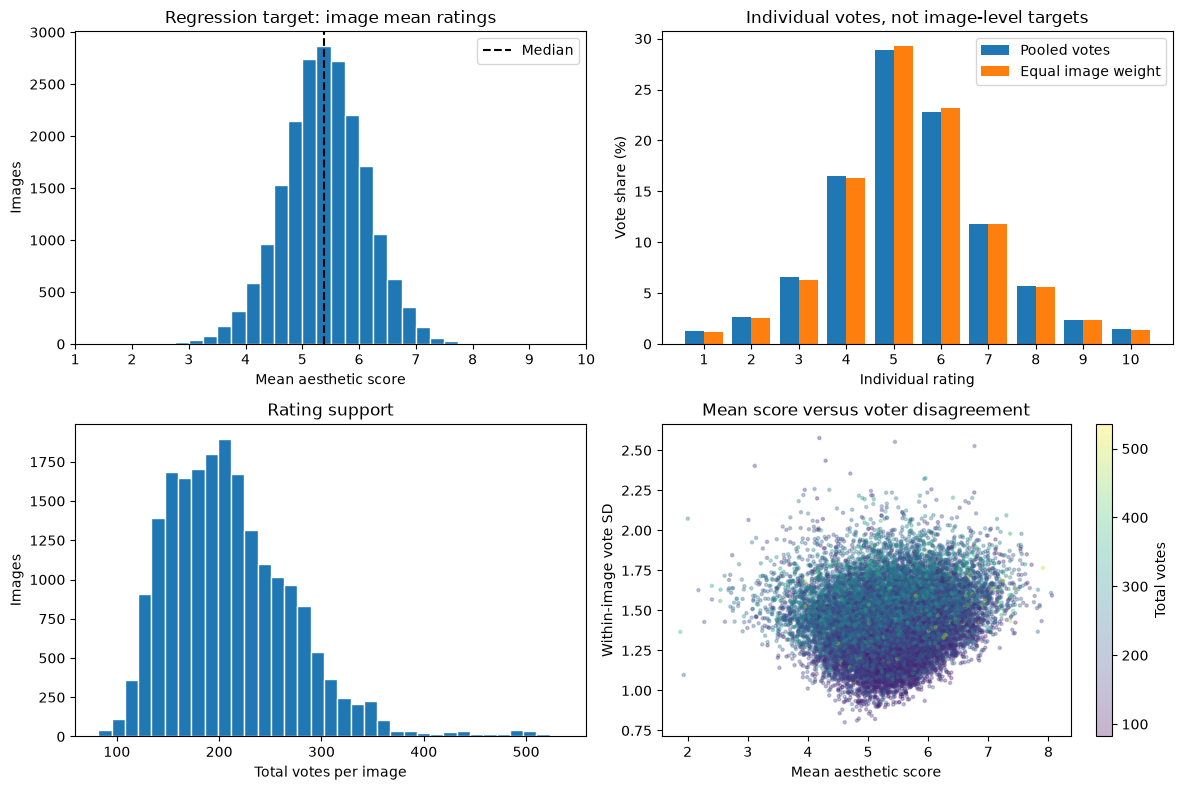

,image_id,mean_score,std_score,total_votes
15971,221721,1.880519,1.366105,385
12104,309716,1.935484,1.096910,217
2055,104023,2.003774,2.073186,265
2169,1512,2.181347,1.626613,193
11685,12363,2.277778,1.427936,198


,image_id,mean_score,std_score,total_votes
13927,34000,8.058394,1.592713,137
18329,429294,8.043478,1.609166,230
17569,218759,7.906504,1.765581,492
15976,613913,7.885542,1.432887,166
2817,13873,7.853881,1.525018,219


In [3]:
score_edges = np.arange(1, 11)
score_bin_labels = [f'{left}-{left + 1}' for left in range(1, 10)]
score_bins = pd.cut(y, bins=score_edges, labels=score_bin_labels, include_lowest=True)
bin_counts = pd.Series(score_bins).value_counts(sort=False)
rating_spread = pd.DataFrame({'images': bin_counts, 'percent': 100 * bin_counts / len(df)})
rating_spread.index.name = 'mean score bin (right-inclusive; first includes 1)'
display(rating_spread.round(2))

q05, q95 = np.quantile(y, [0.05, 0.95])
print(f'Observed range: {y.min():.3f}-{y.max():.3f} on a 1-10 scale')
print(f'Central 90%: {q05:.3f}-{q95:.3f}; across-image SD: {y.std(ddof=1):.3f}')
print(f'Share between 4 and 6: {np.mean((y >= 4) & (y <= 6)):.1%}')
print(f'Below 4: {np.mean(y < 4):.1%}; above 7: {np.mean(y > 7):.1%}')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(y, bins=np.linspace(1, 10, 37), edgecolor='white')
axes[0, 0].axvline(np.median(y), color='black', linestyle='--', label='Median')
axes[0, 0].set(xlabel='Mean aesthetic score', ylabel='Images', xlim=(1, 10),
               title='Regression target: image mean ratings')
axes[0, 0].legend()
pooled_share = rating_counts.sum(axis=0) / votes.sum()
image_share = vote_probabilities.mean(axis=0)
axes[0, 1].bar(rating_values - 0.2, 100 * pooled_share, width=0.4, label='Pooled votes')
axes[0, 1].bar(rating_values + 0.2, 100 * image_share, width=0.4, label='Equal image weight')
axes[0, 1].set(xlabel='Individual rating', ylabel='Vote share (%)', xticks=rating_values,
               title='Individual votes, not image-level targets')
axes[0, 1].legend()
axes[1, 0].hist(votes, bins=35, edgecolor='white')
axes[1, 0].set(xlabel='Total votes per image', ylabel='Images', title='Rating support')
scatter = axes[1, 1].scatter(y, df['std_score'], c=votes, s=5, alpha=0.3)
axes[1, 1].set(xlabel='Mean aesthetic score', ylabel='Within-image vote SD',
               title='Mean score versus voter disagreement')
fig.colorbar(scatter, ax=axes[1, 1], label='Total votes')
plt.tight_layout()
plt.show()

display(df.loc[df['mean_score'].sort_values().index[:5],
               ['image_id', 'mean_score', 'std_score', 'total_votes']])
display(df.nlargest(5, 'mean_score')[['image_id', 'mean_score', 'std_score', 'total_votes']])

### Interpretation before modeling

For the current 20,420-image file, the means are concentrated near the middle: roughly 77% lie between 4 and 6; only about 1.3% exceed 7. The central 90% is approximately 4.18-6.58, despite a full observed range near 1.88-8.06. There is variation for regression, but **not balanced coverage of the 1-10 scale**. Use the computed tables above as the source of truth if the file changes.

A constant prediction can therefore achieve a deceptively modest overall RMSE. Compare against a training-mean baseline and inspect errors by score bin. Sparse tail estimates are less reliable. Do not remove or rebalance ratings based on these plots just to improve test scores.

## 3. Nested CV: CURE-like versus K-Means

- Five shuffled outer folds estimate held-out error; three inner folds independently select `k` for each method by lowest validation RMSE. Both methods use identical splits.
- Standardization and 20-component PCA are fitted inside each inner training fold, then refitted on the outer training fold. Only frozen CLIP embeddings and structural features are inputs. Ratings are used only to fit training-cluster means and select hyperparameters.
- The **CURE-like approximation** matches the adjacent notebooks: Ward clustering of at most 2,000 training points, diverse representatives shrunk 20% toward their cluster centroid, then nearest-representative assignment. This is not the original CURE merging algorithm. K-Means fits all training rows. Both predict the mean training rating of the assigned cluster.
- Compare with a mean-only baseline trained on each outer training fold. Every image receives exactly one out-of-fold prediction. No final production model is saved.

Run the following cells after reviewing the rating spread. The default uses the full file and performs 120 inner candidate fits plus ten outer refits. The CURE sample cap controls quadratic Ward-clustering cost; it does not subsample the evaluation data. Fold SD is descriptive, not a confidence interval. Unidentified near-duplicate images or shared photographers could still make random image-level CV optimistic.

In [4]:
SEED = 42
OUTER_FOLDS = 5
INNER_FOLDS = 3
K_VALUES = [5, 8, 10, 12]  # Inner-CV candidates for both methods.
PCA_COMPONENTS = 20

# Fixed CURE settings; rerun from this cell after editing.
CURE_N_REPS = 5
CURE_SHRINK = 0.2
CURE_SAMPLE_CAP = 2000

X_clip = np.stack(df['clip_embedding']).astype(np.float64)
X_struct = np.stack(df['structural_features']).astype(np.float64)
X = np.hstack([X_clip, X_struct])
if X_clip.shape != (len(df), 512) or X_struct.shape != (len(df), 12):
    raise ValueError('Expected 512 CLIP and 12 structural features per image.')
if not np.isfinite(X).all():
    raise ValueError('Feature matrices contain non-finite values.')
print(f'Features: {X.shape}; target: {y.shape}. No rating-derived inputs.')

Features: (20420, 524); target: (20420,). No rating-derived inputs.


In [5]:
class ClusterMeanRegressor(RegressorMixin, BaseEstimator):
    def __init__(self, method='kmeans', n_clusters=8, sample_cap=2000,
                 n_reps=5, shrink=0.2, random_state=42):
        self.method = method
        self.n_clusters = n_clusters
        self.sample_cap = sample_cap
        self.n_reps = n_reps
        self.shrink = shrink
        self.random_state = random_state

    def fit(self, X, y):
        X, y = check_X_y(X, y, y_numeric=True)
        self.n_features_in_ = X.shape[1]
        if not 1 <= self.n_clusters <= len(X):
            raise ValueError('n_clusters must be between 1 and the training size.')
        if self.method == 'kmeans':
            self.clusterer_ = KMeans(
                n_clusters=self.n_clusters, n_init=5, random_state=self.random_state
            ).fit(X)
        elif self.method == 'cure':
            if self.sample_cap < self.n_clusters or self.n_reps < 1 or not 0 <= self.shrink <= 1:
                raise ValueError('Invalid CURE sample cap, representative count, or shrinkage.')
            rng = np.random.default_rng(self.random_state)
            sample = X[rng.choice(len(X), min(self.sample_cap, len(X)), replace=False)]
            labels = AgglomerativeClustering(
                n_clusters=self.n_clusters, linkage='ward'
            ).fit_predict(sample)
            representatives, representative_labels = [], []
            for cluster in range(self.n_clusters):
                points = sample[labels == cluster]
                centroid = points.mean(axis=0)
                chosen = []
                for _ in range(min(self.n_reps, len(points))):
                    if not chosen:
                        distances = np.linalg.norm(points - centroid, axis=1)
                    else:
                        distances = cdist(points, points[chosen]).min(axis=1)
                        distances[chosen] = -np.inf
                    index = int(distances.argmax())
                    chosen.append(index)
                    representatives.append(points[index] + self.shrink * (centroid - points[index]))
                    representative_labels.append(cluster)
            self.representatives_ = np.asarray(representatives)
            self.representative_labels_ = np.asarray(representative_labels)
        else:
            raise ValueError(f'Unknown method: {self.method}')

        labels = self._assign(X)
        counts = np.bincount(labels, minlength=self.n_clusters)
        if (counts == 0).any():
            raise ValueError('A cluster has no assigned training rows; cannot estimate its mean rating.')
        self.cluster_means_ = np.bincount(labels, weights=y, minlength=self.n_clusters) / counts
        return self

    def _assign(self, X):
        if self.method == 'kmeans':
            return self.clusterer_.predict(X)
        return self.representative_labels_[cdist(X, self.representatives_).argmin(axis=1)]

    def predict(self, X):
        check_is_fitted(self, 'cluster_means_')
        X = check_array(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Prediction feature count differs from training.')
        return self.cluster_means_[self._assign(X)]


def make_pipeline(method):
    return Pipeline([
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=PCA_COMPONENTS, svd_solver='randomized', random_state=SEED)),
        ('regressor', ClusterMeanRegressor(
            method=method, sample_cap=CURE_SAMPLE_CAP,
            n_reps=CURE_N_REPS, shrink=CURE_SHRINK, random_state=SEED
        )),
    ])


def regression_metrics(actual, predicted):
    return {
        'rmse': np.sqrt(mean_squared_error(actual, predicted)),
        'mae': mean_absolute_error(actual, predicted),
        'r2': r2_score(actual, predicted),
    }

In [6]:
outer_cv = KFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=SEED)
methods = {'CURE-like': 'cure', 'K-Means': 'kmeans'}
oof_predictions = {name: np.full(len(y), np.nan) for name in ['Mean baseline', *methods]}
outer_fold_id = np.zeros(len(y), dtype=int)
fold_records, tuning_records = [], []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X), start=1):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    outer_fold_id[test_idx] = fold
    inner_cv = list(KFold(
        n_splits=INNER_FOLDS, shuffle=True, random_state=SEED + fold
    ).split(X_train))
    smallest_train = min(len(indices) for indices, _ in inner_cv)
    if max(K_VALUES) > min(smallest_train, CURE_SAMPLE_CAP):
        raise ValueError('Too many clusters for an inner training fold or the CURE sample cap.')
    if PCA_COMPONENTS > min(smallest_train, X.shape[1]):
        raise ValueError('Too many PCA components for an inner training fold.')

    baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)
    oof_predictions['Mean baseline'][test_idx] = baseline_pred
    fold_records.append({
        'fold': fold, 'method': 'Mean baseline', 'best_k': np.nan,
        'inner_rmse': np.nan, 'n_train': len(train_idx), 'n_test': len(test_idx),
        **regression_metrics(y_test, baseline_pred),
    })
    for name, method in methods.items():
        search = GridSearchCV(
            make_pipeline(method), {'regressor__n_clusters': K_VALUES},
            scoring='neg_root_mean_squared_error', cv=inner_cv,
            refit=True, n_jobs=1, error_score='raise',
        ).fit(X_train, y_train)
        prediction = search.predict(X_test)
        oof_predictions[name][test_idx] = prediction
        fold_records.append({
            'fold': fold, 'method': name,
            'best_k': search.best_params_['regressor__n_clusters'],
            'inner_rmse': -search.best_score_,
            'n_train': len(train_idx), 'n_test': len(test_idx),
            **regression_metrics(y_test, prediction),
        })
        for params, score in zip(search.cv_results_['params'], search.cv_results_['mean_test_score']):
            tuning_records.append({
                'fold': fold, 'method': name,
                'k': params['regressor__n_clusters'], 'inner_rmse': -score,
            })
        print(f'Outer fold {fold}/{OUTER_FOLDS} | {name} | '
              f'k={search.best_params_["regressor__n_clusters"]} | '
              f'held-out RMSE={fold_records[-1]["rmse"]:.4f}', flush=True)

if not (outer_fold_id > 0).all() or any(not np.isfinite(p).all() for p in oof_predictions.values()):
    raise RuntimeError('Missing or non-finite out-of-fold predictions.')
fold_scores = pd.DataFrame(fold_records)
tuning_scores = pd.DataFrame(tuning_records)
display(fold_scores)

Outer fold 1/5 | CURE-like | k=12 | held-out RMSE=0.7280


Outer fold 1/5 | K-Means | k=12 | held-out RMSE=0.7247


Outer fold 2/5 | CURE-like | k=12 | held-out RMSE=0.7098


Outer fold 2/5 | K-Means | k=12 | held-out RMSE=0.7070


Outer fold 3/5 | CURE-like | k=12 | held-out RMSE=0.7104


Outer fold 3/5 | K-Means | k=12 | held-out RMSE=0.7047


Outer fold 4/5 | CURE-like | k=10 | held-out RMSE=0.7232


Outer fold 4/5 | K-Means | k=12 | held-out RMSE=0.7138


Outer fold 5/5 | CURE-like | k=12 | held-out RMSE=0.7212


Outer fold 5/5 | K-Means | k=12 | held-out RMSE=0.7174


,fold,method,best_k,inner_rmse,n_train,n_test,rmse,mae,r2
0,1,Mean baseline,NaN,NaN,16336,4084,0.735770,0.579104,-0.000060
1,1,CURE-like,12.0,0.717198,16336,4084,0.728022,0.572669,0.020891
2,1,K-Means,12.0,0.709810,16336,4084,0.724749,0.568496,0.029676
3,2,Mean baseline,NaN,NaN,16336,4084,0.725783,0.571170,-0.000118
4,2,CURE-like,12.0,0.715421,16336,4084,0.709764,0.559027,0.043544
5,2,K-Means,12.0,0.715385,16336,4084,0.707022,0.558229,0.050920
6,3,Mean baseline,NaN,NaN,16336,4084,0.720195,0.567168,-0.000005
7,3,CURE-like,12.0,0.720382,16336,4084,0.710376,0.557180,0.027077
8,3,K-Means,12.0,0.713208,16336,4084,0.704662,0.550977,0.042666
9,4,Mean baseline,NaN,NaN,16336,4084,0.728060,0.577710,-0.000005


## 4. Held-out results and tail errors

Pooled out-of-fold metrics summarize predictions for all images; mean/SD across folds describe split variability. Positive `rmse_improvement_vs_baseline` means improvement over the mean-only baseline. Tail-bin MAE uses held-out predictions only, with counts displayed to avoid overinterpreting tiny bins. Do not tune again using these outer results and call the resulting score an independent test.

rmse                 mae                  r2          
                   mean       std      mean       std      mean       std
method                                                                   
CURE-like      0.718502  0.008093  0.566162  0.007746  0.026613  0.011156
K-Means        0.713529  0.008095  0.561542  0.006995  0.040065  0.007704
Mean baseline  0.728297  0.005901  0.574167  0.004930 -0.000106  0.000141

,rmse,mae,r2,rmse_improvement_vs_baseline
method,,,,
Mean baseline,0.728317,0.574167,-0.000038,0.000000
CURE-like,0.718538,0.566162,0.026634,0.009778
K-Means,0.713566,0.561542,0.040058,0.014750


k                     5         8         10        12
fold method                                           
1    CURE-like  0.720531  0.717596  0.717513  0.717198
     K-Means    0.716637  0.712753  0.711283  0.709810
2    CURE-like  0.724637  0.722711  0.718206  0.715421
     K-Means    0.719533  0.717270  0.716157  0.715385
3    CURE-like  0.725865  0.722618  0.723627  0.720382
     K-Means    0.720133  0.715927  0.715449  0.713208
4    CURE-like  0.718760  0.720142  0.717062  0.717867
     K-Means    0.718991  0.713814  0.714632  0.713185
5    CURE-like  0.724015  0.722985  0.722079  0.719115
     K-Means    0.718894  0.715583  0.713840  0.713069

,images,Mean baseline MAE,CURE-like MAE,K-Means MAE
mean score bin (right-inclusive; first includes 1),,,,
1-2,2,3.477677,3.321418,3.311822
2-3,36,2.670032,2.629250,2.583220
3-4,605,1.672876,1.634329,1.618752
4-5,5253,0.749098,0.727886,0.716825
5-6,10539,0.248153,0.256661,0.261701
6-7,3722,0.958761,0.930735,0.911606
7-8,261,1.859003,1.812369,1.784991
8-9,2,2.664845,2.603686,2.650819
9-10,0,NaN,NaN,NaN


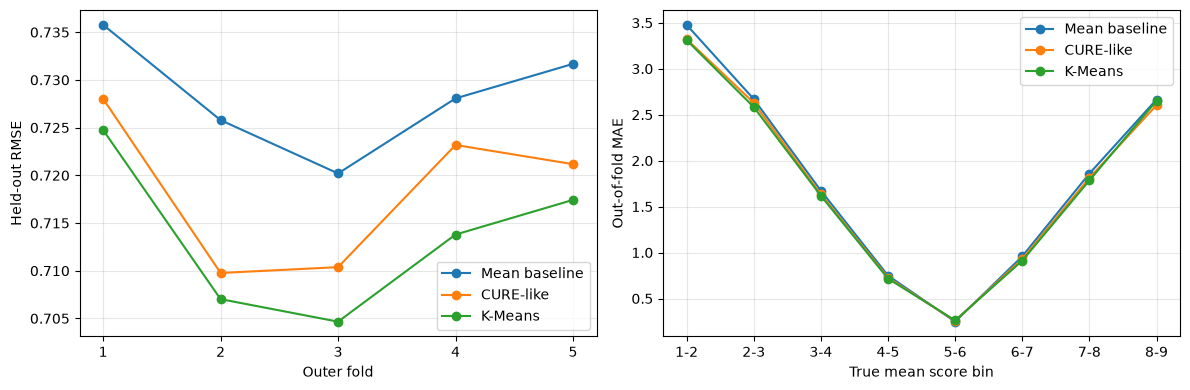

In [7]:
display(fold_scores.groupby('method')[['rmse', 'mae', 'r2']].agg(['mean', 'std']))
pooled_scores = pd.DataFrame([
    {'method': name, **regression_metrics(y, prediction)}
    for name, prediction in oof_predictions.items()
]).set_index('method')
pooled_scores['rmse_improvement_vs_baseline'] = (
    pooled_scores.loc['Mean baseline', 'rmse'] - pooled_scores['rmse']
)
display(pooled_scores)
display(tuning_scores.pivot(index=['fold', 'method'], columns='k', values='inner_rmse'))

oof_results = df[['image_id', 'mean_score']].copy()
oof_results['outer_fold'] = outer_fold_id
oof_results['score_bin'] = score_bins
bin_errors = rating_spread[['images']].copy()
for name, prediction in oof_predictions.items():
    oof_results[f'{name}_prediction'] = prediction
    errors = pd.DataFrame({'score_bin': score_bins, 'absolute_error': np.abs(y - prediction)})
    bin_errors[f'{name} MAE'] = errors.groupby('score_bin', observed=False)['absolute_error'].mean()
display(bin_errors)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in oof_predictions:
    rows = fold_scores[fold_scores['method'] == name]
    axes[0].plot(rows['fold'], rows['rmse'], 'o-', label=name)
    axes[1].plot(score_bin_labels, bin_errors[f'{name} MAE'], 'o-', label=name)
axes[0].set(xlabel='Outer fold', ylabel='Held-out RMSE', xticks=range(1, OUTER_FOLDS + 1))
axes[1].set(xlabel='True mean score bin', ylabel='Out-of-fold MAE')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()